# Week 13 — Ultrasound beamforming: the beam is the Fourier transform of the aperture

An ultrasound probe is an **array of small piezoelectric elements**. Each element radiates a spherical (here, cylindrical) wavelet; the **interference** of those wavelets is the transmitted beam. Two ideas from lecture are simulated here.

1. **Far-field beam pattern = Fourier transform of the aperture.** The element weights $w_n$ at positions $x_n$ give a pattern
   $$B(\sin\theta)=\sum_n w_n\,e^{\,jkx_n\sin\theta},\qquad k=\frac{2\pi}{\lambda},$$
   which is a (discrete) Fourier transform with "spatial frequency" $\sin\theta/\lambda$. A wide aperture gives a narrow beam; a smooth taper (apodization) lowers side lobes.
2. **Delays shape the wavefront.** Firing the elements with a delay profile $\tau_n$ turns the same array into a **plane**, **steered**, **focused (converging)**, or **diverging** transmitter.

Along the way: lateral vs elevation (slice-thickness) resolution, and grating lobes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

c = 1540.0            # speed of sound in soft tissue, m/s
f0 = 3.0e6            # centre frequency, Hz
lam = c / f0          # wavelength, m
k = 2 * np.pi / lam
print(f"wavelength = {lam*1e3:.3f} mm")

def element_positions(N, pitch):
    return (np.arange(N) - (N - 1) / 2) * pitch

def pattern_direct(x, weights, theta):
    """Far-field pattern |sum_n w_n exp(j k x_n sin(theta))| by explicit summation."""
    return np.abs(np.exp(1j * k * np.outer(np.sin(theta), x)) @ weights)

def to_db(a, floor=-60):
    a = a / a.max()
    return np.maximum(20 * np.log10(a + 1e-12), floor)

wavelength = 0.513 mm


## 1. A wider aperture gives a narrower beam

Elements are spaced $\lambda/2$ apart (the usual pitch for a phased array). We sum the element phasors for 16, 32 and 64 elements, all with equal weights (a rectangular aperture).

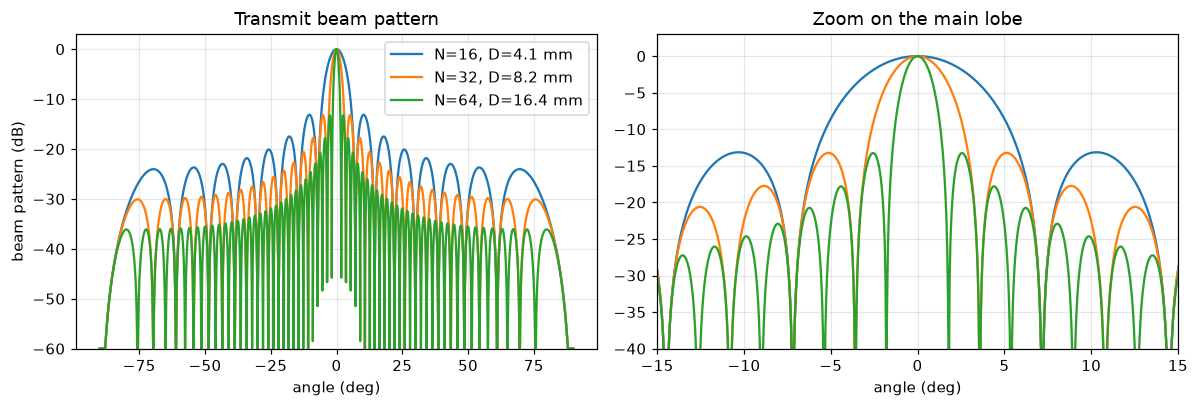

N= 16  D=  4.1 mm   -6 dB width =  8.64 deg   theory 1.2*lam/D =  8.59 deg
N= 32  D=  8.2 mm   -6 dB width =  4.23 deg   theory 1.2*lam/D =  4.30 deg
N= 64  D= 16.4 mm   -6 dB width =  2.07 deg   theory 1.2*lam/D =  2.15 deg


In [2]:
theta = np.linspace(-np.pi / 2, np.pi / 2, 4001)
pitch = lam / 2

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for N in (16, 32, 64):
    x = element_positions(N, pitch)
    ax[0].plot(np.degrees(theta), to_db(pattern_direct(x, np.ones(N), theta)),
               label=f'N={N}, D={N*pitch*1e3:.1f} mm')
    ax[1].plot(np.degrees(theta), to_db(pattern_direct(x, np.ones(N), theta)))
ax[0].set(xlabel='angle (deg)', ylabel='beam pattern (dB)', ylim=(-60, 3), title='Transmit beam pattern')
ax[0].legend()
ax[1].set(xlim=(-15, 15), ylim=(-40, 3), xlabel='angle (deg)', title='Zoom on the main lobe')
plt.tight_layout(); plt.show()

# -6 dB (half-amplitude) main-lobe width versus theory ~ 1.2 * lambda / D
for N in (16, 32, 64):
    x = element_positions(N, pitch)
    p = to_db(pattern_direct(x, np.ones(N), theta))
    idx = np.where(p >= -6)[0]
    w_deg = np.degrees(theta[idx[-1]] - theta[idx[0]])
    D = N * pitch
    print(f"N={N:3d}  D={D*1e3:5.1f} mm   -6 dB width = {w_deg:5.2f} deg   theory 1.2*lam/D = {np.degrees(1.2*lam/D):5.2f} deg")

## 2. The pattern really is a Fourier transform

Zero-padding the element weights and taking an FFT evaluates $\sum_n w_n e^{-j2\pi f_x x_n}$ at spatial frequencies $f_x$. With $f_x=\sin\theta/\lambda$ and pitch $\lambda/2$, the FFT axis covers exactly $\sin\theta\in[-1,1)$. We compare it with the explicit phasor sum.

max |FFT - direct| = 1.3105835861004778e-15


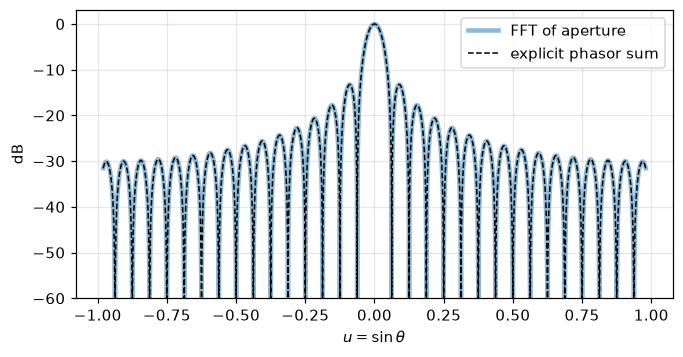

In [3]:
Nfft = 8192
N = 32
w = np.ones(N)
A = np.fft.fftshift(np.fft.fft(w, Nfft))                  # FFT of the aperture
u = np.fft.fftshift(np.fft.fftfreq(Nfft, d=pitch)) * lam  # u = sin(theta)

keep = np.abs(u) < 0.98
th = np.arcsin(u[keep])
direct = pattern_direct(element_positions(N, pitch), w, th)

fft_n = np.abs(A[keep]) / np.abs(A[keep]).max()
dir_n = direct / direct.max()
print("max |FFT - direct| =", np.abs(fft_n - dir_n).max())

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(u[keep], to_db(np.abs(A[keep])), lw=3, alpha=0.5, label='FFT of aperture')
ax.plot(u[keep], to_db(direct), 'k--', lw=1, label='explicit phasor sum')
ax.set(xlabel=r'$u=\sin\theta$', ylabel='dB', ylim=(-60, 3)); ax.legend(); plt.show()

## 3. Apodization: trade main-lobe width for side lobes

A rectangular aperture is a "box", whose Fourier transform is a sinc with $-13$ dB side lobes. Tapering the edge weights (Hann, Hamming) lowers the side lobes but widens the main lobe, which is the same trade-off as windowing in spectral analysis.

      window  -6 dB width (u)  peak side lobe (dB)
 rectangular            0.075                -13.2
     Hamming            0.116                -41.8
        Hann            0.121                -31.5


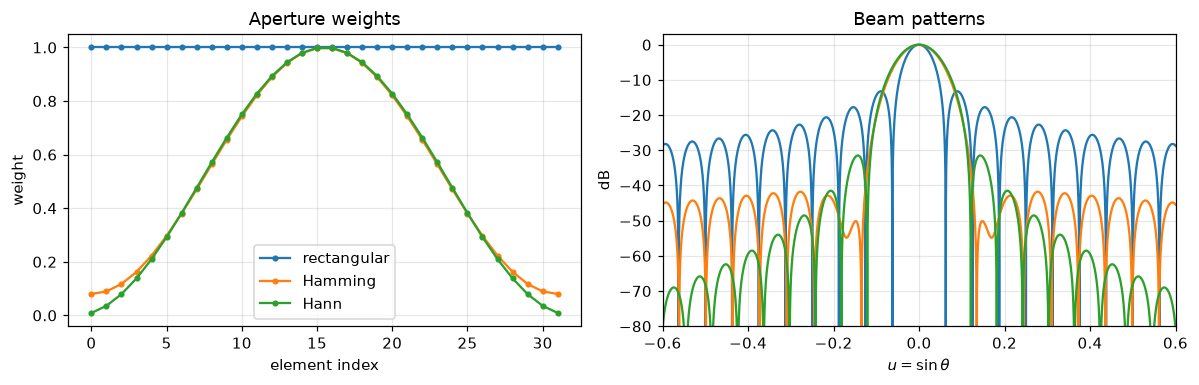

In [4]:
N = 32
n = np.arange(N)
windows = {
    'rectangular': np.ones(N),
    'Hamming': np.hamming(N),
    'Hann': np.hanning(N + 2)[1:-1],
}

def lobe_stats(wts, Nfft=16384):
    A = np.abs(np.fft.fftshift(np.fft.fft(wts, Nfft)))
    uu = np.fft.fftshift(np.fft.fftfreq(Nfft, d=pitch)) * lam
    db = to_db(A, -120)
    half = uu >= 0
    p, uh = db[half], uu[half]
    first_null = np.argmax(np.diff(p) > 0)             # first local minimum from the centre
    sidelobe = p[first_null:].max()
    width6 = 2 * uh[np.where(p >= -6)[0][-1]]
    return uu, db, sidelobe, width6

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
print(f"{'window':>12s} {'-6 dB width (u)':>16s} {'peak side lobe (dB)':>20s}")
for name, wts in windows.items():
    uu, db, sl, w6 = lobe_stats(wts)
    ax[0].plot(n, wts, 'o-', ms=3, label=name)
    ax[1].plot(uu, db, label=name)
    print(f"{name:>12s} {w6:16.3f} {sl:20.1f}")
ax[0].set(xlabel='element index', ylabel='weight', title='Aperture weights'); ax[0].legend()
ax[1].set(xlim=(-0.6, 0.6), ylim=(-80, 3), xlabel=r'$u=\sin\theta$', ylabel='dB', title='Beam patterns')
plt.tight_layout(); plt.show()

## 4. Steering and grating lobes

Applying a linear phase ramp $w_n\rightarrow w_ne^{-jkx_n\sin\theta_0}$ steers the beam to $\theta_0$. If the element **pitch is larger than $\lambda/2$**, the pattern repeats and a **grating lobe** appears at
$$\sin\theta_g=\sin\theta_0-m\frac{\lambda}{\text{pitch}}.$$
The aperture is held at $16\lambda$ while the pitch changes.

pitch 0.5*lambda: grating lobes at [] deg
pitch 1.0*lambda: grating lobes at [-35.3] deg
pitch 2.0*lambda: grating lobes at [67.3, -4.4, -35.3] deg


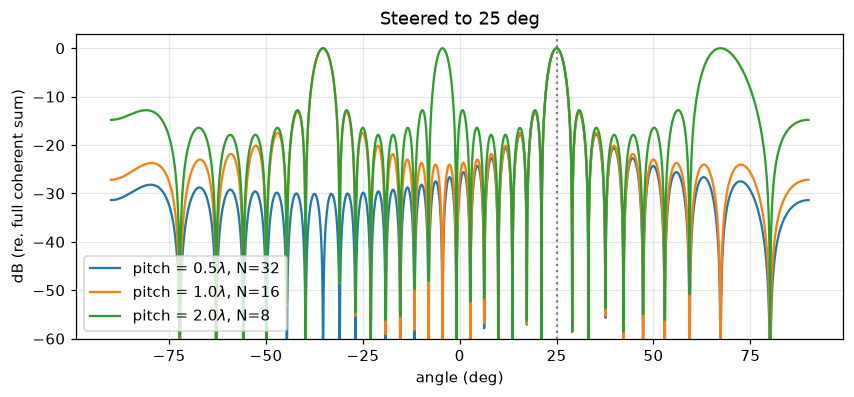

In [5]:
theta0 = np.radians(25)
fig, ax = plt.subplots(figsize=(9, 3.6))
for p_lam in (0.5, 1.0, 2.0):
    Ne = int(16 / p_lam)
    x = element_positions(Ne, p_lam * lam)
    wts = np.exp(-1j * k * x * np.sin(theta0))
    pat = pattern_direct(x, wts, theta) / Ne
    ax.plot(np.degrees(theta), 20 * np.log10(pat + 1e-6), label=f'pitch = {p_lam}$\\lambda$, N={Ne}')
    # expected grating lobe(s) in the visible region
    gl = [np.degrees(np.arcsin(np.sin(theta0) - m / p_lam)) for m in (-2, -1, 1, 2)
          if abs(np.sin(theta0) - m / p_lam) <= 1]
    print(f"pitch {p_lam}*lambda: grating lobes at {[round(float(g), 1) for g in gl]} deg")
ax.axvline(25, color='gray', ls=':')
ax.set(xlabel='angle (deg)', ylabel='dB (re. full coherent sum)', ylim=(-60, 3), title='Steered to 25 deg')
ax.legend(); plt.show()

## 5. Delay laws: plane, steered, focused, diverging

Element $n$ at $(x_n,0)$ fires after delay $\tau_n$. At a point $\mathbf r$ the continuous-wave (single-frequency) field is
$$p(\mathbf r)=\sum_n w_n\frac{e^{-j\,(k\,r_n+2\pi f_0\tau_n)}}{\sqrt{r_n}},\qquad r_n=|\mathbf r-\mathbf x_n|.$$
We choose:

| wavefront | delays $\tau_n$ |
|---|---|
| plane (steered by $\theta_0$) | $\tau_n=x_n\sin\theta_0/c$ (shifted to be $\ge 0$) |
| focused at $\mathbf F$ | $\tau_n=(R_{\max}-R_n)/c,\ R_n=\lvert\mathbf F-\mathbf x_n\rvert$ — far elements fire first |
| diverging from a virtual source $\mathbf V$ behind the array | $\tau_n=(R_n-R_{\min})/c,\ R_n=\lvert\mathbf V-\mathbf x_n\rvert$ — near elements fire first |

aperture D = 16.4 mm


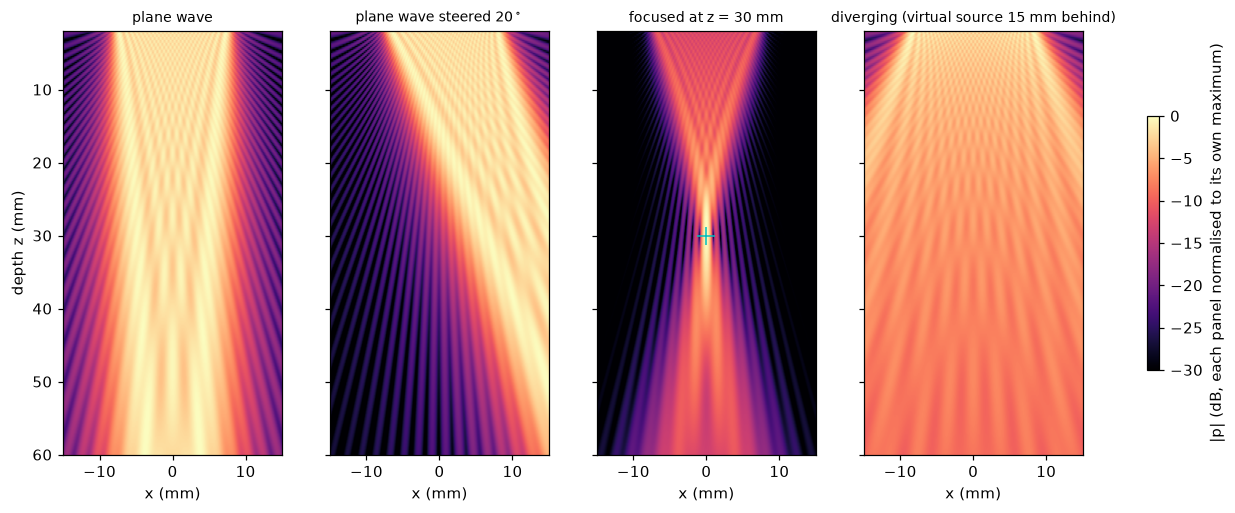

In [6]:
def cw_field(xe, delays, X, Z, apod=None):
    """Monochromatic field of a line array (elements on z=0) at points (X, Z)."""
    if apod is None:
        apod = np.ones(len(xe))
    P = np.zeros(np.broadcast(X, Z).shape, complex)
    for xn, tn, wn in zip(xe, delays, apod):
        r = np.sqrt((X - xn) ** 2 + Z ** 2)
        P += wn * np.exp(-1j * (k * r + 2 * np.pi * f0 * tn)) / np.sqrt(r)
    return P

N = 64
xe = element_positions(N, pitch)
D = N * pitch
print(f"aperture D = {D*1e3:.1f} mm")

xg = np.arange(-15e-3, 15e-3 + 1e-9, 0.1e-3)
zg = np.arange(2e-3, 60e-3 + 1e-9, 0.2e-3)
X, Z = np.meshgrid(xg, zg)

F = np.array([0.0, 30e-3])
RF = np.hypot(F[0] - xe, F[1])
V = np.array([0.0, -15e-3])
RV = np.hypot(V[0] - xe, V[1])
th0 = np.radians(20)
tau_plane = np.zeros(N)
tau_steer = xe * np.sin(th0) / c; tau_steer -= tau_steer.min()
tau_focus = (RF.max() - RF) / c
tau_div = (RV - RV.min()) / c

cases = [('plane wave', tau_plane), ('plane wave steered 20$^\\circ$', tau_steer),
         ('focused at z = 30 mm', tau_focus), ('diverging (virtual source 15 mm behind)', tau_div)]

fig, axs = plt.subplots(1, 4, figsize=(15, 5), sharey=True)
for ax, (title, tau) in zip(axs, cases):
    P = np.abs(cw_field(xe, tau, X, Z))
    im = ax.imshow(to_db(P, -30), extent=[xg[0]*1e3, xg[-1]*1e3, zg[-1]*1e3, zg[0]*1e3],
                   aspect='equal', cmap='magma', vmin=-30, vmax=0)
    ax.set_title(title, fontsize=9); ax.set_xlabel('x (mm)'); ax.grid(False)
axs[0].set_ylabel('depth z (mm)')
axs[2].plot(0, 30, 'c+', ms=12)
fig.colorbar(im, ax=axs, shrink=0.6, label='|p| (dB, each panel normalised to its own maximum)')
plt.show()

### Focal width scales with $\lambda F/D$

For a rectangular aperture, the $-6$ dB lateral width at the focus is $\approx1.2\,\lambda F/D$, so a **lower f-number** ($F/D$) gives a **finer focus**. We measure it numerically for several focal depths.

 F (mm)   F/D  measured (mm)  1.2*lam*F/D (mm)
     20  1.22           0.79              0.75
     30  1.83           1.15              1.12
     45  2.74           1.71              1.69
     60  3.65           2.27              2.25


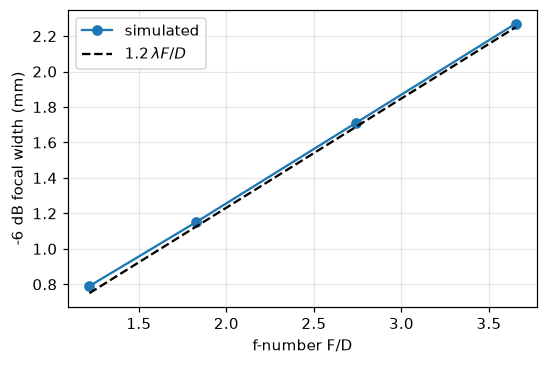

In [7]:
xs = np.linspace(-4e-3, 4e-3, 1601)
print(f"{'F (mm)':>7s} {'F/D':>5s} {'measured (mm)':>14s} {'1.2*lam*F/D (mm)':>17s}")
widths = []
Fs = np.array([20e-3, 30e-3, 45e-3, 60e-3])
for Fz in Fs:
    R = np.hypot(0 - xe, Fz)
    tau = (R.max() - R) / c
    p = np.abs(cw_field(xe, tau, xs, Fz))
    p = to_db(p, -60)
    idx = np.where(p >= -6)[0]
    wm = xs[idx[-1]] - xs[idx[0]]
    widths.append(wm)
    print(f"{Fz*1e3:7.0f} {Fz/D:5.2f} {wm*1e3:14.2f} {1.2*lam*Fz/D*1e3:17.2f}")

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(Fs/D, np.array(widths)*1e3, 'o-', label='simulated')
ax.plot(Fs/D, 1.2*lam*Fs/D*1e3, 'k--', label=r'$1.2\,\lambda F/D$')
ax.set(xlabel='f-number F/D', ylabel='-6 dB focal width (mm)'); ax.legend(); plt.show()

## 6. A 2-D aperture: lateral vs elevation resolution

A real probe is a 2-D patch: many elements in the **lateral** direction, but only a few rows in **elevation** (the out-of-plane direction). The beam is the 2-D Fourier transform of the aperture, so a narrow elevation aperture gives a wide elevation beam, which is why **slice thickness** is much coarser than in-plane resolution.

lateral aperture    16.4 mm -> -6 dB beam width at F=30 mm:  1.05 mm
elevation aperture   2.1 mm -> -6 dB slice thickness at F=30 mm:  9.02 mm


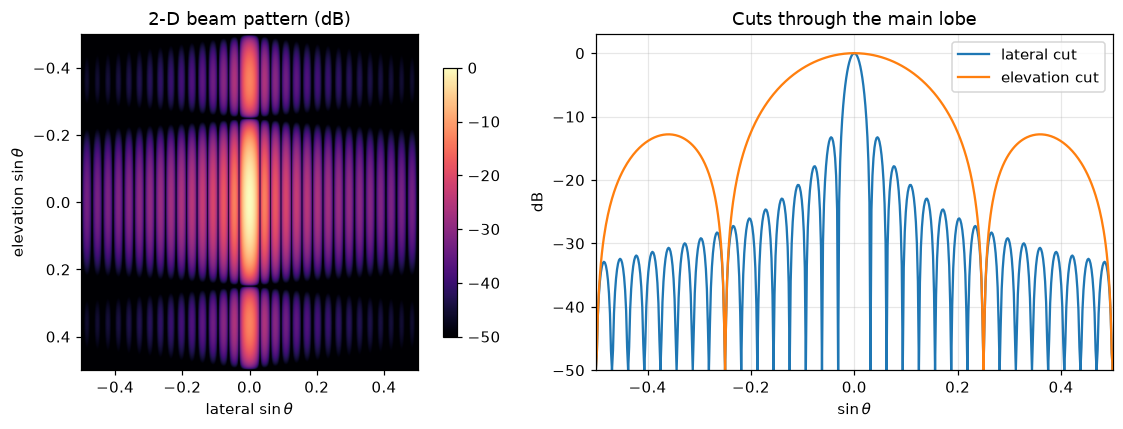

In [8]:
Nlat, Nel = 64, 8
ap = np.ones((Nel, Nlat))          # rows = elevation, columns = lateral
Nf = 1024
A2 = np.fft.fftshift(np.fft.fft2(ap, s=(Nf, Nf)))
u = np.fft.fftshift(np.fft.fftfreq(Nf, d=pitch)) * lam
B2 = to_db(np.abs(A2), -50)

lat = B2[Nf // 2, :]
ele = B2[:, Nf // 2]
def w6(profile):
    idx = np.where(profile >= -6)[0]
    return u[idx[-1]] - u[idx[0]]

Fz = 30e-3
print(f"lateral aperture   {Nlat*pitch*1e3:5.1f} mm -> -6 dB beam width at F=30 mm: {w6(lat)*Fz*1e3:5.2f} mm")
print(f"elevation aperture {Nel*pitch*1e3:5.1f} mm -> -6 dB slice thickness at F=30 mm: {w6(ele)*Fz*1e3:5.2f} mm")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
im = ax[0].imshow(B2, extent=[u[0], u[-1], u[-1], u[0]], cmap='magma', vmin=-50, vmax=0)
ax[0].set(xlim=(-0.5, 0.5), ylim=(0.5, -0.5), xlabel=r'lateral $\sin\theta$', ylabel=r'elevation $\sin\theta$',
          title='2-D beam pattern (dB)'); ax[0].grid(False)
fig.colorbar(im, ax=ax[0], shrink=0.8)
ax[1].plot(u, lat, label='lateral cut')
ax[1].plot(u, ele, label='elevation cut')
ax[1].set(xlim=(-0.5, 0.5), ylim=(-50, 3), xlabel=r'$\sin\theta$', ylabel='dB', title='Cuts through the main lobe')
ax[1].legend(); plt.tight_layout(); plt.show()

## Summary

* The transmit beam is the **Fourier transform of the aperture**: aperture width $D$ sets the main-lobe width ($\approx\lambda/D$ in angle, $\approx1.2\lambda F/D$ at a focus); the **taper** sets the side lobes.
* **Delays** convert the same array into plane, steered, focused, or diverging transmitters. Focusing is only as narrow as the f-number allows.
* **Pitch above $\lambda/2$** creates grating lobes when steering.
* The **elevation aperture** is small, so **slice thickness** is the coarsest dimension, which is why 2-D arrays and 3-D probes matter.

Next: [Ultrasound_Doppler.ipynb](Ultrasound_Doppler.ipynb) (velocity from the frequency shift) and [Ultrasound_Speckle_Tracking.ipynb](Ultrasound_Speckle_Tracking.ipynb) (speckle statistics, filtering, and tracking).